<a href="https://colab.research.google.com/github/sayantansikdar/indic-medvqa-xling/blob/main/notebooks/run_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Indic Med-VQA: layer-wise diagnosis and band-targeted recovery

**Runtime → Change runtime type → L4** (A100 also works; T4/V100 do not — Gemma 3 needs bf16).

How to use this notebook:
- **After any restart or disconnect, run cells 0, 1 and 2 first**, then continue at the step you were on.
- Every cell is safe to rerun: finished work (data, translations, predictions, caches, adapters) is detected on Drive and skipped.
- To pick up a new version of this notebook: **File → Open notebook → GitHub → `sayantansikdar/indic-medvqa-xling`**. Code-only updates arrive by rerunning cell 1.

## 0. GPU, Drive and paths

In [10]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import os, json
import pandas as pd
from IPython.display import Image, display
from google.colab import drive
drive.mount('/content/drive')
R = '/content/drive/MyDrive/xling/runs'      # all outputs (data, caches, adapters, reports)
D = f'{R}/data'
T = f'{R}/medgemma/arogyabodha/test/base'    # Phase A cache, test split
C = f'{R}/medgemma/arogyabodha/calib/base'   # Phase A cache, calib split
TR = f'{R}/train'                            # adapters
PY = '/content/it2env/bin/python'            # translation-only environment (cell 4)
REPO = '/content/indic-medvqa-xling'
MT = 'hi-mt,bn-mt,ta-mt,te-mt'; X = 'MedXpertQA_MM_test'
os.environ['XLING_RUNS'] = R
os.makedirs(D, exist_ok=True)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Code and dependencies (also: rerun to pull code updates) — expect `22 passed`

In [11]:
if not os.path.exists(REPO):
    !git clone -q https://github.com/sayantansikdar/indic-medvqa-xling.git {REPO}
%cd {REPO}
!git pull -q
!pip install -q -r requirements.txt
!python -m pytest -q tests 2>&1 | tail -1

/content/indic-medvqa-xling
26 passed, 1 warning in 14.70s


## 2. Hugging Face login
Needs a read token from an account that has accepted the terms for
[MedGemma 1.5 4B](https://huggingface.co/google/medgemma-1.5-4b-it),
[IndicTrans2 en→indic](https://huggingface.co/ai4bharat/indictrans2-en-indic-1B) and
[IndicTrans2 indic→en](https://huggingface.co/ai4bharat/indictrans2-indic-en-1B).

In [12]:
from huggingface_hub import login
login()

## 3. Data (≈ 30–40 min the first time; skipped once built)
Items present in EN + HI + BN + TA + TE with one image and the same answer key; split by image hash (test/calib/train 50/20/30).

In [ ]:
if not os.path.exists(f'{D}/arogyabodha.jsonl'):
    !python -m xling.data arogyabodha --out {D}
if not os.path.exists(f'{D}/vqarad.jsonl'):
    !python -m xling.data vqarad --out {D}
L = ['hi', 'bn', 'ta', 'te']
items = [json.loads(l) for l in open(f'{D}/arogyabodha.jsonl')]
test = [i for i in items if i['split'] == 'test']
print(len(items), 'items; splits:', {s: sum(i['split'] == s for i in items) for s in ['test', 'calib', 'train']})
print('mt :', {l: sum(f'{l}-mt' in i['text'] for i in items) for l in L})
print('tt :', {l: sum(f'{l}-tt' in i['text'] for i in test) for l in L}, 'of', len(test), 'test items')

## 4. Translation with IndicTrans2 (≈ 1–2 h the first time; skipped once done)
`*-mt`: IndicTrans2 from the English source (main Indic condition). `*-tt`: translate-test baseline B1 (test split).
Runs in a separate environment (Python 3.12, torch 2.7.1, transformers 4.53.3) because IndicTrans2's code does not work with transformers 5.
Expect `ENV_OK 2.7.1+cu126 True 4.53.3` first.

In [ ]:
%cd {REPO}
ok = !{PY} -c "import torch, transformers, IndicTransToolkit.processor; print('ENV_OK', torch.__version__, torch.cuda.is_available(), transformers.__version__)" 2>/dev/null
if not any(l.startswith('ENV_OK') for l in ok):
    !uv --version >/dev/null 2>&1 || pip install -q uv
    !rm -rf /content/it2env
    !uv venv -q --python 3.12 /content/it2env
    !uv pip install -q --python {PY} torch==2.7.1 -r requirements-translate.txt
    ok = !{PY} -c "import torch, transformers, IndicTransToolkit.processor; print('ENV_OK', torch.__version__, torch.cuda.is_available(), transformers.__version__)"
print('\n'.join(ok))
assert any(l.startswith('ENV_OK') for l in ok), "translation environment is broken - send the output above"
!{PY} -m xling.translate forward  --items {D}/arogyabodha.jsonl
!{PY} -m xling.translate backward --items {D}/arogyabodha.jsonl --from-variant mt --split test
!{PY} -m xling.translate forward  --items {D}/vqarad.jsonl

## 5. Phase A — zero-shot baseline (B0) + residual / lens / attention cache (≈ 2.5–3 h; skipped once done)
Prints one `acc=… n=… letter mass=…` line per condition, then the report tables (all items, and without MedXpertQA).

In [ ]:
COND = 'en,hi-mt,bn-mt,ta-mt,te-mt,hi-mixed,bn-mixed,ta-mixed,te-mixed'
!python -m xling.infer --items {D}/arogyabodha.jsonl --split calib --conds {COND} --capture
!python -m xling.infer --items {D}/arogyabodha.jsonl --split test  --conds {COND} --capture --fidelity 100
!python -m xling.infer --items {D}/arogyabodha.jsonl --split test  --conds hi-tt,bn-tt,ta-tt,te-tt,hi-pure,bn-pure,ta-pure,te-pure
!python -m xling.infer --items {D}/vqarad.jsonl --split test
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base --exclude-sources MedXpertQA_MM_test
!python -m xling.report --root {R}/medgemma/vqarad/test --base base

## 6. Phase B1–B4 — diagnosis from the cache (≈ 15 min CPU; the first time also ≈ 40 min GPU to cache residuals in bf16; skipped once done)

test: 1601 items present in all of ['en', 'hi-mt', 'bn-mt', 'ta-mt', 'te-mt']
calib: 631 items present in all of ['en', 'hi-mt', 'bn-mt', 'ta-mt', 'te-mt']
B1 drift / CKA
B2 probes (PCA-128 + logistic regression per layer)
B3 logit lens
B4 visual attention
wrote /content/drive/MyDrive/xling/runs/medgemma/arogyabodha/test/base/diagnosis_mt.csv
test: 1667 items present in all of ['en', 'hi-mixed', 'bn-mixed', 'ta-mixed', 'te-mixed']
calib: 660 items present in all of ['en', 'hi-mixed', 'bn-mixed', 'ta-mixed', 'te-mixed']
B1 drift / CKA
B2 probes (PCA-128 + logistic regression per layer)
B3 logit lens
B4 visual attention
wrote /content/drive/MyDrive/xling/runs/medgemma/arogyabodha/test/base/diagnosis_mixed.csv

drift_centred
cond   bn-mt  hi-mt  ta-mt  te-mt
layer                            
0      0.946  1.294  1.210  1.324
3      1.133  1.398  1.337  1.400
6      0.801  0.960  1.206  0.999
9      0.723  1.081  1.191  0.952
12     0.842  0.927  0.939  1.014
15     0.733  0.843  0.887  0.

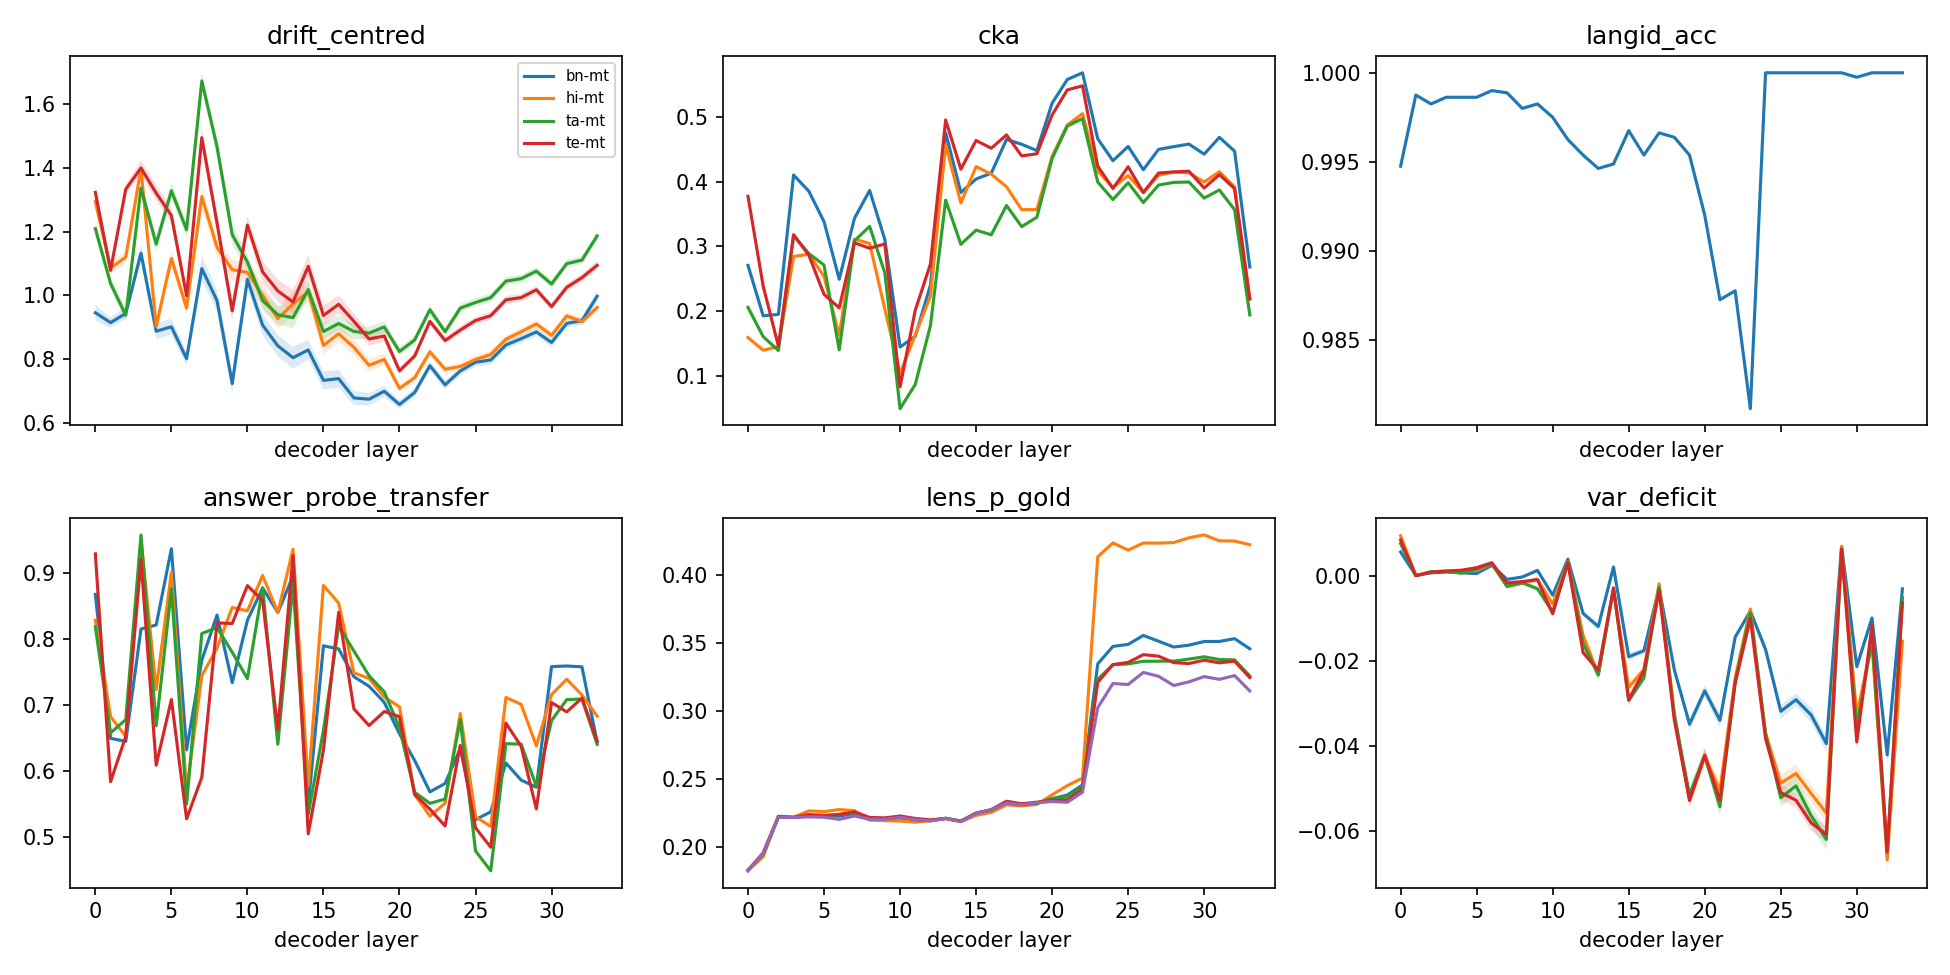

In [ ]:
for v in ['mt', 'mixed']:
    f = f'{T}/diagnosis_{v}.csv'
    if not os.path.exists(f) or 'lang_var_share' not in open(f).read():   # rerun when new measures are missing
        !python -m xling.diagnose --test-dir {T} --calib-dir {C} --variant {v} --plot
df = pd.read_csv(f'{T}/diagnosis_mt.csv')
def table(m):
    print('\n' + m); print(df[(df.metric == m) & (df.layer >= 0)].pivot(index='layer', columns='cond', values='value').iloc[::3].round(3).to_string())
for m in ['drift_centred', 'drift_langcentred', 'cka', 'lang_var_share', 'answer_probe_acc', 'answer_probe_transfer', 'var_deficit', 'lens_p_gold']:
    table(m)
print('\nemergence layer'); print(df[df.metric.str.startswith('emergence')][['metric', 'cond', 'value', 'lo', 'hi']].round(1).to_string(index=False))
display(Image(f'{T}/diagnosis_mt.png'))


## 7. Phase B5 — activation patching and the critical band B* (measured: ≈ 60–70 s per item on L4; resumes)
B* is chosen on **calib** (MedXpertQA excluded) and frozen; the test-split run reports the pre-registered H2 check for that band.

config.json: 100% 2.55k/2.55k [00:00<00:00, 6.50MB/s]
model.safetensors.index.json: 100% 90.6k/90.6k [00:00<00:00, 38.5MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/4.96G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/8.60G [00:00<?, ?B/s]
Reconstructing (incomplete total...):  48% 4.09G/8.60G [00:12<00:12, 369MB/s,  244MB/s  ]
Reconstructing (incomplete total...):  64% 5.52G/8.60G [00:19<00:11, 259MB/s,  369MB/s  ]
Reconstructing (incomplete total...):  83% 7.13G/8.60G [00:19<00:03, 462MB/s,  259MB/s  ]
Reconstructing (incomplete total...): 100% 8.60G/8.60G [00:23<00:00, 440MB/s,  462MB/s  ]

Fetching 2 files: 100% 2/2 [00:25<00:00, 12.91s/it]
Download complete: 100% 7.79G/7.79G [00:25<00:00, 302MB/s,  302MB/s  ]
Download complete: 100% 7.79G/7.79G [00:25<00:00, 300MB/s,  302MB/s  ]
Reconstruction complete: 100% 8.60G/8.60G [00:2

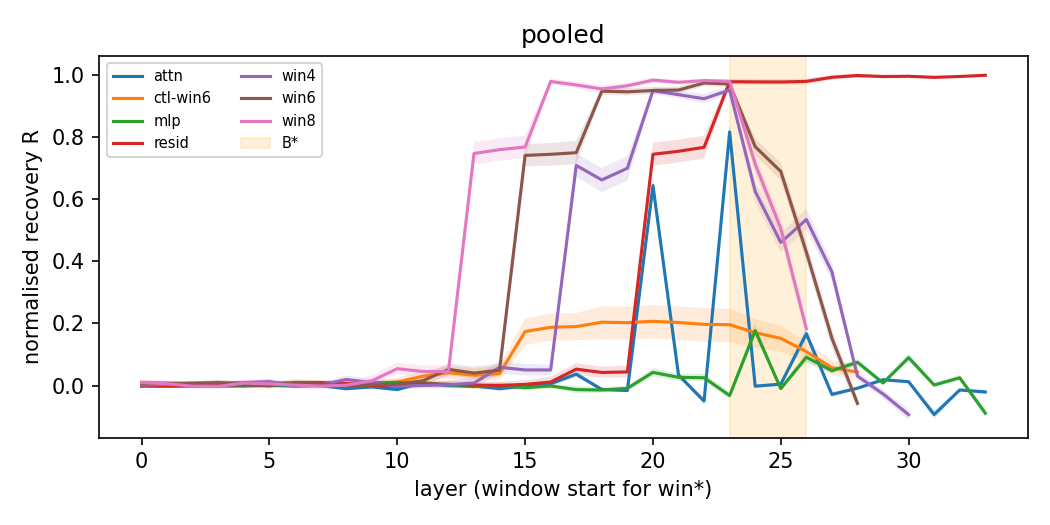

In [ ]:
!python -m xling.patching --items {D}/arogyabodha.jsonl --split calib --conds {MT} --max-items 150 --exclude-sources {X}
!python -m xling.band --patch-dir {R}/medgemma/arogyabodha/calib/patching --plot
!python -m xling.patching --items {D}/arogyabodha.jsonl --split test --conds {MT} --max-items 150 --exclude-sources {X} --modes resid,attn,mlp,win4,win6,win8,ctl-win6,rev-win6
!python -m xling.band --patch-dir {R}/medgemma/arogyabodha/test/patching --plot
display(Image(f'{R}/medgemma/arogyabodha/calib/patching/recovery_pooled.png'))

## 8. Baseline B3 — training-free steering (≈ 30 min sweep on calib + ≈ 40 min test evaluation on L4)
Sweep: layers 16–26 (around the causal band), scales 1 and 2, 100 calib items per language.

In [ ]:
!python -m xling.steer --items {D}/arogyabodha.jsonl --variant mt --vectors {C}/steer_mt.npz --layers 16:28:2 --alphas 1,2 --limit 100
best = json.load(open(f'{C}/steer_sweep_mt.json'))['best']; print('best:', best)
!python -m xling.infer --items {D}/arogyabodha.jsonl --split test --conds en,{MT} --tag steer --steer-file {C}/steer_mt.npz --steer-layer {best['layer']} --steer-alpha {best['alpha']}

## 9. Phase C — adapters (measured ≈ 1 h each on L4, 2,000 pairs; finished adapters are skipped)
Main method: `ours_c` = LoRA on B* + **centred** alignment loss (raw cosine is ≈ 0.99 for any pair on Gemma 3, so the
first `ours`/`random_band` runs barely used their alignment term; they are kept as the raw-cosine variant).
A1 `random_band_c` uses the same centred loss on a random band; A2 and B4 have no alignment term.

In [ ]:
BAND = f'{R}/medgemma/arogyabodha/calib/patching/band.json'
common = f'--items {D}/arogyabodha.jsonl --band-json {BAND} --max-pairs 2000 --seed 0'
!python -m xling.train {common} --placement band   --lam 0.5 --align centred --out {TR}/ours_c
!python -m xling.train {common} --placement random --lam 0.5 --align centred --out {TR}/random_band_c
!python -m xling.train {common} --placement band   --lam 0   --out {TR}/band_noalign
!python -m xling.train {common} --placement all    --lam 0   --match-budget --out {TR}/all_layers
!python -m xling.train {common} --placement band   --lam 0.5 --align raw --out {TR}/ours

## 10. Phase D — evaluate every adapter and write the report tables (measured-rate estimate ≈ 45 min per adapter on L4)
All adapters on English + the four mt conditions; the main method also on the code-mixed conditions.

In [ ]:
RUNS = ['ours_c', 'random_band_c', 'band_noalign', 'all_layers', 'ours']
for tag in RUNS:
    conds = 'en,' + MT + (',hi-mixed,bn-mixed,ta-mixed,te-mixed' if tag == 'ours_c' else '')
    !python -m xling.infer --items {D}/arogyabodha.jsonl --split test --conds {conds} --adapter {TR}/{tag} --tag {tag}
    !python -m xling.infer --items {D}/vqarad.jsonl --split test --adapter {TR}/{tag} --tag {tag}
RS = 'steer,' + ','.join(RUNS[::-1])
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base --runs {RS}
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base --runs {RS} --exclude-sources {X}
!python -m xling.report --root {R}/medgemma/vqarad/test --base base --runs {','.join(RUNS[::-1])}

## 10b. Paired adapter-vs-adapter tests (CPU, ≈ 1 min; needs cell 10 finished)
Each pair is A vs B on the items both answered: per-language exact McNemar (Holm over languages) and a pooled row per
variant that averages each item's A−B difference over the four languages (sign-flip permutation, items independent).
Band placement vs controls (`random_band_c`, `all_layers`) and the alignment ablation (`ours_c` vs `band_noalign`).
Written to `paired*.md` / `paired*.csv` next to the reports.

In [ ]:
PAIRS = ','.join(f'{a}:{b}' for a in ['ours_c', 'ours', 'band_noalign'] for b in ['random_band_c', 'all_layers']) + ',ours_c:band_noalign'
!python -m xling.report --root {R}/medgemma/arogyabodha/test --compare {PAIRS} --exclude-sources {X}
!python -m xling.report --root {R}/medgemma/vqarad/test --compare {PAIRS}
!python -m xling.report --root {R}/medgemma/arogyabodha/test --compare {PAIRS}

## 10c. Second seed: is the out-of-domain gap robust? (≈ 2 h training + ≈ 10 min VQA-RAD on L4; finished work is skipped)
Retrains `ours_c` and `random_band_c` with `--seed 1` (new training-pair order and, for the control, a **new random band**),
evaluates both on VQA-RAD only, and repeats the paired tests within seed 1, across seeds, and seed 0 vs seed 1.
Last line: mean alignment loss vs target CE for both seeds' runs, from `train_log.jsonl` (seed 0 has no log - its losses were only printed in cell 9).

In [13]:
BAND = f'{R}/medgemma/arogyabodha/calib/patching/band.json'
s1 = f'--items {D}/arogyabodha.jsonl --band-json {BAND} --max-pairs 2000 --seed 1'
!python -m xling.train {s1} --placement band   --lam 0.5 --align centred --out {TR}/ours_c_s1
!python -m xling.train {s1} --placement random --lam 0.5 --align centred --out {TR}/random_band_c_s1
for tag in ['ours_c', 'ours_c_s1', 'random_band_c', 'random_band_c_s1']:
    print(f'{tag:17s} adapted layers', json.load(open(f'{TR}/{tag}/train_config.json'))['adapted_layers'])
for tag in ['ours_c_s1', 'random_band_c_s1']:
    !python -m xling.infer --items {D}/vqarad.jsonl --split test --adapter {TR}/{tag} --tag {tag}
V = f'{R}/medgemma/vqarad/test'
!python -m xling.report --root {V} --base base --runs ours,all_layers,band_noalign,random_band_c,ours_c,random_band_c_s1,ours_c_s1
P1 = 'ours_c_s1:random_band_c_s1,ours_c_s1:random_band_c,ours_c:random_band_c_s1,ours_c_s1:all_layers,ours_c:ours_c_s1,random_band_c:random_band_c_s1'
!python -m xling.report --root {V} --compare {P1} --name paired_seed1
for tag in ['ours_c_s1', 'random_band_c_s1']:
    log = pd.read_json(f'{TR}/{tag}/train_log.jsonl', lines=True)
    print(f'{tag:17s} mean ce_tg={log.ce_tg.mean():.4f}  align={log["align"].mean():.4f}  0.5*align/ce_tg={0.5 * log["align"].mean() / log.ce_tg.mean():.3f}')

Loading weights: 100% 883/883 [00:02<00:00, 416.35it/s] 
EN anchors:   6% 53/919 [00:50<13:22,  1.08it/s]/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
EN anchors: 100% 919/919 [14:32<00:00,  1.05it/s]
/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(
adapted layers 23..26 (4), rank 8, align on [23, 24, 25, 26]
trainable params 524,288 = 0.0122% of 4,300,603,760
step 32: ce_tg=3.4985  ce_en=4.3260  align=2.6465
step 64: ce_tg=2.9879  ce_en=3.8812  align=2.8959
step 96: ce_tg=2.4197  ce_en=3.1470  align=2.6077
step 128: ce_tg=3.4296  ce_en=3.6977  align=2.6770
step 160: ce_tg=2.5352  ce_en=2.

## 11. (If compute allows) Qwen2.5-VL-7B control — baseline + diagnosis

In [ ]:
MT5 = 'en,hi-mt,bn-mt,ta-mt,te-mt'
!python -m xling.infer --model qwen25vl --items {D}/arogyabodha.jsonl --split calib --conds {MT5} --capture
!python -m xling.infer --model qwen25vl --items {D}/arogyabodha.jsonl --split test  --conds {MT5} --capture
!python -m xling.diagnose --test-dir {R}/qwen25vl/arogyabodha/test/base --calib-dir {R}/qwen25vl/arogyabodha/calib/base --variant mt --plot

## Appendix — fallback translator (only if IndicTrans2 cannot be used)
NLLB-200 runs in the main environment. Use one engine for all languages.

In [ ]:
# !python -m xling.translate forward  --engine nllb --items {D}/arogyabodha.jsonl
# !python -m xling.translate backward --engine nllb --items {D}/arogyabodha.jsonl --from-variant mt --split test
# !python -m xling.translate forward  --engine nllb --items {D}/vqarad.jsonl